In [2]:
import pandas as pd
import numpy as np

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt

# Set manual seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# 1. Load MNIST Dataset
transform = transforms.Compose([transforms.ToTensor()])
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# 2. Define Baseline CNN
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.fc = nn.Sequential(
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)

# 3. Training Loop Helper
def train_model(model, loader, epochs=2):
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()
    model.train()
    for epoch in range(epochs):
        for images, labels in loader:
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
    return model

# Train baseline model
baseline_model = SimpleCNN()
baseline_model = train_model(baseline_model, train_loader, epochs=2)
baseline_model.eval()

100%|██████████| 9.91M/9.91M [00:00<00:00, 14.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 406kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.73MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.3MB/s]


SimpleCNN(
  (conv): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc): Sequential(
    (0): Linear(in_features=1568, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [6]:
def fgsm_attack(image, epsilon, data_grad):
    perturbed_image = image + epsilon * data_grad.sign()
    perturbed_image = torch.clamp(perturbed_image, 0, 1)
    return perturbed_image

def pgd_attack(model, image, label, epsilon, alpha, iterations):
    perturbed_image = image.clone().detach().requires_grad_(True)
    for _ in range(iterations):
        # Random start
        if _ == 0:
            perturbed_image = perturbed_image + torch.empty_like(perturbed_image).uniform_(-epsilon, epsilon)
            perturbed_image = torch.clamp(perturbed_image, 0, 1).detach().requires_grad_(True)

        output = model(perturbed_image)
        loss = nn.CrossEntropyLoss()(output, label)
        model.zero_grad()
        loss.backward()

        data_grad = perturbed_image.grad.data
        perturbed_image = perturbed_image + alpha * data_grad.sign()
        # Projection
        eta = torch.clamp(perturbed_image - image, min=-epsilon, max=epsilon)
        perturbed_image = torch.clamp(image + eta, min=0, max=1).detach().requires_grad_(True)

    return perturbed_image

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import numpy as np

def evaluate_attacks(model, loader, epsilons):
    results = {eps: {'fgsm_corr': 0, 'pgd_corr': 0, 'total': 0} for eps in epsilons}

    for images, labels in loader:
        for i in range(len(images)):
            img, label = images[i:i+1], labels[i:i+1]
            img = img.clone().detach().requires_grad_(True)

            output = model(img)
            init_pred = output.max(1, keepdim=True)[1]
            if init_pred.item() != label.item():
                continue

            loss = nn.CrossEntropyLoss()(output, label)
            model.zero_grad()
            loss.backward()

            # FGSM
            for eps in epsilons:
                if eps == 0:
                    results[eps]['fgsm_corr'] += 1
                    results[eps]['pgd_corr'] += 1
                    results[eps]['total'] += 1
                    continue

                perturbed_fgsm = fgsm_attack(img, eps, img.grad.data)
                output_fgsm = model(perturbed_fgsm)
                final_pred_fgsm = output_fgsm.max(1, keepdim=True)[1]
                if final_pred_fgsm.item() == label.item():
                    results[eps]['fgsm_corr'] += 1

                # PGD
                perturbed_pgd = pgd_attack(model, img, label, eps, eps/4.0, 10)
                output_pgd = model(perturbed_pgd)
                final_pred_pgd = output_pgd.max(1, keepdim=True)[1]
                if final_pred_pgd.item() == label.item():
                    results[eps]['pgd_corr'] += 1

                results[eps]['total'] += 1

    return results

# Run evaluation on the test set (limit to a subset of 1000 images to speed up execution if needed)
subset_indices = list(range(1000))
subset_test_dataset = torch.utils.data.Subset(test_dataset, subset_indices)
fast_test_loader = DataLoader(subset_test_dataset, batch_size=64, shuffle=False)

epsilons = [0.0, 0.05, 0.10, 0.20, 0.30]
results = evaluate_attacks(baseline_model, fast_test_loader, epsilons)

print("-------------------------------")
print(" EPSILON   FGSM ACC    PGD ACC")
print("-------------------------------")
for eps in epsilons:
    total = results[eps]['total']
    fgsm_acc = (results[eps]['fgsm_corr'] / total) * 100 if total > 0 else 0
    pgd_acc = (results[eps]['pgd_corr'] / total) * 100 if total > 0 else 0
    print(f" {eps:.2f}       {fgsm_acc:.1f} %      {pgd_acc:.1f} %")
print("-------------------------------")

-------------------------------
 EPSILON   FGSM ACC    PGD ACC
-------------------------------
 0.00       100.0 %      100.0 %
 0.05       95.8 %      93.9 %
 0.10       79.8 %      65.2 %
 0.20       23.8 %      0.7 %
 0.30       1.9 %      0.0 %
-------------------------------


In [9]:
# 4. Adversarial Training
def train_adversarial(model, loader, epochs=2):
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()
    model.train()
    for epoch in range(epochs):
        for images, labels in loader:
            images = images.clone().detach().requires_grad_(True)
            outputs = model(images)
            loss = criterion(outputs, labels)
            model.zero_grad()
            loss.backward()

            # Generate adversarial images on-the-fly with FGSM (eps=0.20)
            perturbed_images = fgsm_attack(images, 0.20, images.grad.data)

            # Train on perturbed images
            optimizer.zero_grad()
            outputs_adv = model(perturbed_images)
            loss_adv = criterion(outputs_adv, labels)
            loss_adv.backward()
            optimizer.step()
    return model

adv_model = SimpleCNN()
adv_model = train_adversarial(adv_model, train_loader, epochs=2)
adv_model.eval()

# Evaluate adversarial model
results_adv = evaluate_attacks(adv_model, fast_test_loader, epsilons)

print("----------------------------------------------------")
print("MODEL              CLEAN    FGSM(0.20)   PGD(0.20)")
print("----------------------------------------------------")
def get_pct(res_dict, eps, key):
    tot = res_dict[eps]['total']
    return f"{(res_dict[eps][key]/tot)*100:.1f} %"

print(f"Baseline           {get_pct(results, 0.0, 'fgsm_corr')}     {get_pct(results, 0.2, 'fgsm_corr')}       {get_pct(results, 0.2, 'pgd_corr')}")
print(f"Adversarially      {get_pct(results_adv, 0.0, 'fgsm_corr')}     {get_pct(results_adv, 0.2, 'fgsm_corr')}       {get_pct(results_adv, 0.2, 'pgd_corr')}")
print("----------------------------------------------------")

----------------------------------------------------
MODEL              CLEAN    FGSM(0.20)   PGD(0.20)
----------------------------------------------------
Baseline           100.0 %     23.8 %       0.7 %
Adversarially      100.0 %     90.7 %       11.5 %
----------------------------------------------------


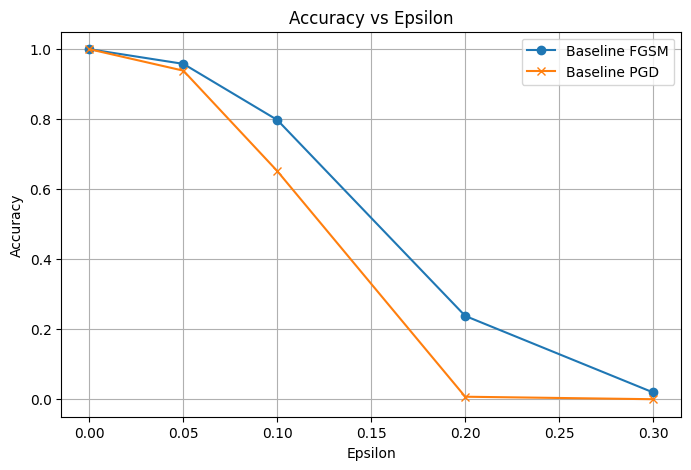

In [10]:
# 5. Visualization and Plots
eps_list = [0.0, 0.05, 0.10, 0.20, 0.30]
baseline_fgsm = [results[eps]['fgsm_corr']/results[eps]['total'] for eps in eps_list]
baseline_pgd = [results[eps]['pgd_corr']/results[eps]['total'] for eps in eps_list]

plt.figure(figsize=(8, 5))
plt.plot(eps_list, baseline_fgsm, 'o-', label='Baseline FGSM')
plt.plot(eps_list, baseline_pgd, 'x-', label='Baseline PGD')
plt.xlabel('Epsilon')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Epsilon')
plt.legend()
plt.grid(True)
plt.savefig('accuracy_vs_epsilon.png')
plt.show()

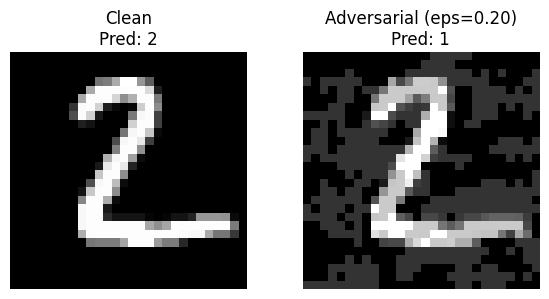

In [11]:
import matplotlib.pyplot as plt

# Find a misclassified digit to save as required by the document ('clean_vs_adversarial.png')
baseline_model.eval()
images, labels = next(iter(test_loader))
found = False
for i in range(len(images)):
    img, label = images[i:i+1], labels[i:i+1]
    img.requires_grad = True
    output = baseline_model(img)
    init_pred = output.max(1, keepdim=True)[1]
    if init_pred.item() == label.item():
        loss = nn.CrossEntropyLoss()(output, label)
        baseline_model.zero_grad()
        loss.backward()
        perturbed_img = fgsm_attack(img, 0.20, img.grad.data)
        output_adv = baseline_model(perturbed_img)
        adv_pred = output_adv.max(1, keepdim=True)[1]
        if adv_pred.item() != label.item():
            fig, axes = plt.subplots(1, 2, figsize=(6, 3))
            axes[0].imshow(img.squeeze().detach().numpy(), cmap='gray')
            axes[0].set_title(f"Clean\nPred: {init_pred.item()}")
            axes[0].axis('off')

            axes[1].imshow(perturbed_img.squeeze().detach().numpy(), cmap='gray')
            axes[1].set_title(f"Adversarial (eps=0.20)\nPred: {adv_pred.item()}")
            axes[1].axis('off')

            plt.tight_layout()
            plt.savefig('clean_vs_adversarial.png')
            plt.show()
            found = True
            break
if not found:
    print("Could not find a suitable sample. Please re-run.")